# Applied Spatial Ecology: Predicting Invasive Plant Establishment Risk of Pyrus calleryana (2025 vs. 2050)

## Environment Setup and Package Installation
Install the required spatial analysis, geospatial data processing, and visualization libraries. 

- **`rasterio`**: For handling raster datasets (environmental and climate layers).
- **`geopandas`**: For spatial vector manipulation of occurrence data.
- **`contextily`**: For adding basemaps to geographic plots.
- **`matplotlib` / `pandas` / `numpy` / `scikit-learn`**: Core scientific computing, modeling, and visualization stack.

In [1]:
!pip install rasterio geopandas contextily matplotlib pandas numpy scikit-learn

## Initialize Working Environment & Set Relative Paths
Import core Python libraries for data processing and define the relative directory path (`DATA`) where all raster and vector inputs are stored.

In [2]:
import os
import numpy as np
import pandas as pd
import rasterio
from rasterio.plot import show
import geopandas as gpd
import matplotlib.pyplot as plt

# Define relative path to your DATA directory
DATA_DIR = 'DATA'

print("Environment setup complete!")

Environment setup complete!


## 1. Load and Clean *Pyrus calleryana* Occurrence Data
Load GBIF occurrence records for *Pyrus calleryana* (Bradford Pear), remove records lacking valid geographic coordinates, and convert the cleaned records into a `GeoDataFrame` with a standard WGS84 coordinate reference system (`EPSG:4326`).

In [3]:
gbif_path = os.path.join(DATA_DIR, 'pyrus_calleryana_gbif.csv')

# Load tab-delimited GBIF occurrence data
df = pd.read_csv(gbif_path, sep='\t', low_memory=False)

# Filter out rows missing coordinates
df_clean = df.dropna(subset=['decimalLatitude', 'decimalLongitude']).copy()

# Convert to GeoDataFrame (WGS84 / EPSG:4326)
gdf_occurrences = gpd.GeoDataFrame(
    df_clean, 
    geometry=gpd.points_from_xy(df_clean.decimalLongitude, df_clean.decimalLatitude),
    crs="EPSG:4326"
)

print(f"Total valid presence points loaded: {len(gdf_occurrences)}")

Total valid presence points loaded: 176811


## 2. Load Baseline Environmental & Land Cover Datasets
Load the baseline (current) environmental predictors from the `DATA` directory:
- **Bioclimatic Variables**:
  - `Bio1`: Annual Mean Temperature
  - `Bio6`: Min Temperature of Coldest Month
  - `Bio12`: Annual Precipitation
  - `Bio15`: Precipitation Seasonality
- **Land Cover**: NLCD (National Land Cover Database) raster layer.

Inspect the Spatial Reference Systems (CRS) and array dimensions to ensure compatibility across datasets.

In [4]:
clim_files = {
    'Bio1':  os.path.join(DATA_DIR, 'bio1_annual_mean_temp.tif'),
    'Bio6':  os.path.join(DATA_DIR, 'bio6_min_temp_coldest_month.tif'),
    'Bio12': os.path.join(DATA_DIR, 'bio12_annual_precip.tif'),
    'Bio15': os.path.join(DATA_DIR, 'bio15_precip_seasonality.tif')
}

clim_datasets = {}
for var_name, filepath in clim_files.items():
    clim_datasets[var_name] = rasterio.open(filepath)
    print(f"{var_name} CRS: {clim_datasets[var_name].crs} | Shape: {clim_datasets[var_name].shape}")

# Load NLCD Land Cover
landcover_path = os.path.join(DATA_DIR, 'nlcd_landcover.tif')
landcover_src = rasterio.open(landcover_path)
print(f"NLCD Land Cover CRS: {landcover_src.crs} | Shape: {landcover_src.shape}")

Bio1 CRS: EPSG:4326 | Shape: (1080, 2160)
Bio6 CRS: EPSG:4326 | Shape: (1080, 2160)
Bio12 CRS: EPSG:4326 | Shape: (1080, 2160)
Bio15 CRS: EPSG:4326 | Shape: (1080, 2160)
NLCD Land Cover CRS: PROJCS["AEA        WGS84",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",23],PARAMETER["longitude_of_center",-96],PARAMETER["standard_parallel_1",29.5],PARAMETER["standard_parallel_2",45.5],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]] | Shape: (5000, 5000)


## 3. Load Future Climate Projections (2050 - SSP2-4.5)
Extract corresponding future bioclimatic predictors for the year 2050 under the SSP2-4.5 Shared Socioeconomic Pathway (`worldclim_2050_ssp245.tif`).

Extract specific bands matching our baseline climate variables:
- **Band 1**: 2050 Annual Mean Temp (`Bio1`)
- **Band 6**: 2050 Min Temp Coldest Month (`Bio6`)
- **Band 12**: 2050 Annual Precip (`Bio12`)
- **Band 15**: 2050 Precip Seasonality (`Bio15`)

In [5]:
future_clim_path = os.path.join(DATA_DIR, 'worldclim_2050_ssp245.tif')

with rasterio.open(future_clim_path) as future_src:
    print(f"2050 Multi-band raster contains {future_src.count} total bands.")
    
    # Extract specific bioclimatic bands
    bio1_2050  = future_src.read(1)   # Band 1: Annual Mean Temp
    bio6_2050  = future_src.read(6)   # Band 6: Min Temp Coldest Month
    bio12_2050 = future_src.read(12)  # Band 12: Annual Precip
    bio15_2050 = future_src.read(15)  # Band 15: Precip Seasonality

print("2050 Future climate bands successfully extracted into memory!")

2050 Multi-band raster contains 19 total bands.
2050 Future climate bands successfully extracted into memory!


## 4. Spatial Filtering and Presence Record Cleaning
Filter occurrence points against raster land cover/environmental masks to remove invalid, background, or ocean/water coordinates. 

Visualize the final cleaned presence point distribution across the target study region.

--> Initial occurrences: 176811
--> Removed 176674 ocean/water/background points.
--> Clean land occurrence count: 137


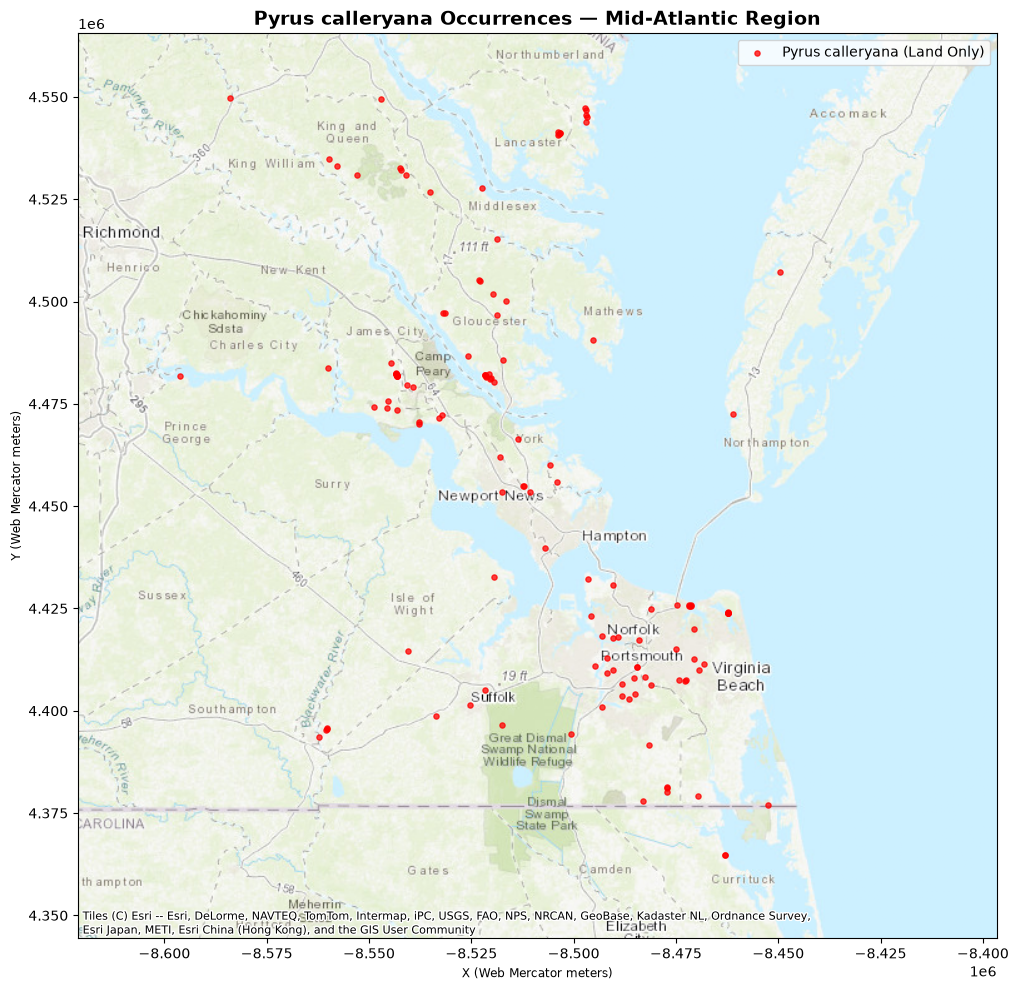

In [6]:
import os
import warnings
import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
import contextily as cx
import matplotlib.pyplot as plt
from shapely.geometry import box

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

# 1. Identify active occurrences dataset
if 'df_gbif' in globals():
    occ_df = df_gbif
elif 'gdf_occurrences' in globals():
    occ_df = gdf_occurrences
elif 'occurrences_df' in globals():
    occ_df = occurrences_df
elif 'df' in globals():
    occ_df = df
else:
    raise NameError("Could not locate occurrences dataset. Make sure your data loading cell ran!")

# Ensure DataFrame is a clean copy
occ_df = occ_df.copy()

# 2. Convert points to GeoDataFrame in WGS84 (lat/lon)
if isinstance(occ_df, gpd.GeoDataFrame):
    gdf_4326 = occ_df.to_crs(epsg=4326)
else:
    gdf_4326 = gpd.GeoDataFrame(
        occ_df,
        geometry=gpd.points_from_xy(occ_df['decimalLongitude'], occ_df['decimalLatitude']),
        crs="EPSG:4326"
    )

# 3. Open NLCD raster & Reproject Points to NLCD's Native CRS before sampling
nlcd_path = os.path.join(DATA_DIR, 'nlcd_landcover.tif')

with rasterio.open(nlcd_path) as landcover_src:
    nlcd_crs = landcover_src.crs
    nlcd_bounds = landcover_src.bounds
    
    # Transform points to NLCD's native CRS (e.g., EPSG:5070 / Albers)
    gdf_nlcd_crs = gdf_4326.to_crs(nlcd_crs)
    
    # Sample NLCD using coordinates matched to the raster's projection
    coords_nlcd = zip(gdf_nlcd_crs.geometry.x, gdf_nlcd_crs.geometry.y)
    nlcd_values = [val[0] for val in landcover_src.sample(coords_nlcd)]

# 4. Attach sampled landcover class and filter out open water (11) and background (0, 255)
gdf_4326['nlcd_class'] = nlcd_values

initial_count = len(gdf_4326)
gdf_clean = gdf_4326[
    (gdf_4326['nlcd_class'] > 0) & 
    (gdf_4326['nlcd_class'] != 11) & 
    (gdf_4326['nlcd_class'] < 250)
].copy()

print(f"--> Initial occurrences: {initial_count}")
print(f"--> Removed {initial_count - len(gdf_clean)} ocean/water/background points.")
print(f"--> Clean land occurrence count: {len(gdf_clean)}")

# 5. Convert clean points to Web Mercator (EPSG:3857) for plotting with contextily basemap
gdf_web = gdf_clean.to_crs(epsg=3857)

# Calculate NLCD raster extent in Web Mercator meters
raster_box = box(*nlcd_bounds)
bounds_series = gpd.GeoSeries([raster_box], crs=nlcd_crs).to_crs(epsg=3857)
bounds = bounds_series.total_bounds  # [xmin, ymin, xmax, ymax]

# 6. Render Basemap Plot
fig, ax = plt.subplots(figsize=(12, 10))

gdf_web.plot(
    ax=ax,
    color='red',
    markersize=14,
    alpha=0.75,
    label='Pyrus calleryana (Land Only)'
)

# Constrain map extent to NLCD tile
ax.set_xlim(bounds[0], bounds[2])
ax.set_ylim(bounds[1], bounds[3])

# Add Esri World Topo Basemap
cx.add_basemap(ax, source=cx.providers.Esri.WorldTopoMap)

plt.title("Pyrus calleryana Occurrences — Mid-Atlantic Region", fontsize=14, fontweight='bold')
plt.xlabel("X (Web Mercator meters)")
plt.ylabel("Y (Web Mercator meters)")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 5. Background / Pseudo-Absence Point Sampling
Generate random pseudo-absence points within the extent of the study area bounding box using the native NLCD spatial reference system. Pseudo-absences provide the background environmental contrast necessary to train binary classification models.

In [7]:
import numpy as np
import geopandas as gpd

# Set seed for reproducibility
np.random.seed(42)

# Extract bounding box limits from NLCD raster in its native CRS (EPSG:5070)
xmin, ymin, xmax, ymax = landcover_src.bounds
num_presences = len(gdf_occurrences)

# Generate random points within the bounding box
rand_x = np.random.uniform(xmin, xmax, num_presences)
rand_y = np.random.uniform(ymin, ymax, num_presences)

# Create Pseudo-Absence GeoDataFrame in EPSG:5070
gdf_pseudo = gpd.GeoDataFrame(
    {'presence': np.zeros(num_presences, dtype=int)},
    geometry=gpd.points_from_xy(rand_x, rand_y),
    crs=landcover_src.crs
)

print(f"Generated {len(gdf_pseudo)} pseudo-absence points across tile H28V10.")

Generated 176811 pseudo-absence points across tile H28V10.


## 6. Environmental Feature Extraction & Dataset Preparation
Extract present bioclimatic variables (`Bio1`, `Bio6`, `Bio12`, `Bio15`) and land cover values (`NLCD`) at both presence and pseudo-absence coordinate locations. 

Combine the sampled values into a consolidated training DataFrame and clean missing/invalid (`NoData`) values.

In [14]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from shapely.geometry import Point

# 1. Ensure valid pseudo-absence points (matching presence count)
n_pres = len(gdf_occurrences)
xmin, ymin, xmax, ymax = gdf_occurrences.total_bounds

# Generate random points within the bounding box of occurrences
np.random.seed(42)
rand_x = np.random.uniform(xmin, xmax, n_pres)
rand_y = np.random.uniform(ymin, ymax, n_pres)
pseudo_geometry = [Point(x, y) for x, y in zip(rand_x, rand_y)]

gdf_pseudo = gpd.GeoDataFrame(geometry=pseudo_geometry, crs=gdf_occurrences.crs)

# 2. Environmental Data Extraction Function
def extract_environmental_data(gdf, presence_val):
    # Extract coordinates in baseline raster CRS (WGS84 - EPSG:4326)
    coords_wgs = [(x, y) for x, y in zip(gdf.geometry.x, gdf.geometry.y)]
    
    # Reproject coordinates for NLCD raster (Albers Equal Area - EPSG:5070)
    gdf_5070 = gdf.to_crs("EPSG:5070")
    coords_nlcd = [(x, y) for x, y in zip(gdf_5070.geometry.x, gdf_5070.geometry.y)]
    
    # Sample baseline climate rasters
    bio1_vals = [val[0] for val in clim_datasets['Bio1'].sample(coords_wgs)]
    bio6_vals = [val[0] for val in clim_datasets['Bio6'].sample(coords_wgs)]
    bio12_vals = [val[0] for val in clim_datasets['Bio12'].sample(coords_wgs)]
    bio15_vals = [val[0] for val in clim_datasets['Bio15'].sample(coords_wgs)]
    
    # Sample NLCD Land Cover raster safely
    landcover_path = os.path.join(DATA_DIR, 'nlcd_landcover.tif')
    with rasterio.open(landcover_path) as src:
        nlcd_vals = [val[0] for val in src.sample(coords_nlcd)]
        
    df_extracted = pd.DataFrame({
        'Bio1': bio1_vals,
        'Bio6': bio6_vals,
        'Bio12': bio12_vals,
        'Bio15': bio15_vals,
        'NLCD': nlcd_vals,
        'target': presence_val
    })
    
    return df_extracted

print("Extracting raster values for presence points...")
df_pres = extract_environmental_data(gdf_occurrences, presence_val=1)

print("Extracting raster values for pseudo-absence points...")
df_abs = extract_environmental_data(gdf_pseudo, presence_val=0)

# Combine into master training dataset
df_model = pd.concat([df_pres, df_abs], ignore_index=True)

# Replace extreme climate NoData values (-9999, -32768) with NaN
df_model[['Bio1', 'Bio6', 'Bio12', 'Bio15']] = df_model[['Bio1', 'Bio6', 'Bio12', 'Bio15']].replace([-9999, -32768], np.nan)
df_model = df_model.dropna(subset=['Bio1', 'Bio6', 'Bio12', 'Bio15']).reset_index(drop=True)

# Filter out out-of-bound climate pixels
df_model = df_model[df_model['Bio1'] > -50].reset_index(drop=True)

print(f"\nFinal clean training dataset ready! Shape: {df_model.shape}")
print("\nClass Balance Distribution:")
print(df_model['target'].value_counts())
df_model.head()

Extracting raster values for presence points...
Extracting raster values for pseudo-absence points...

Final clean training dataset ready! Shape: (240157, 6)

Class Balance Distribution:
target
1    175148
0     65009
Name: count, dtype: int64


,Bio1,Bio6,Bio12,Bio15,NLCD,target
0,18.347979,1.99050,1434.0,20.473492,250,1
1,14.091281,-5.44400,1096.0,33.116180,250,1
2,12.551937,-7.77575,1011.0,43.279457,250,1
3,12.788125,-7.67350,963.0,44.339149,250,1
4,12.699229,-7.54000,1005.0,42.961182,250,1


## 7. Model Training, Evaluation, and Feature Importance
Split the dataset into training and testing subsets using stratified sampling. Train a **Regularized Random Forest Classifier** to predict habitat suitability and evaluate model performance using **ROC-AUC** and classification report metrics.

--- Regularized Model Performance ---
ROC-AUC Score: 0.9974

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.95      0.96     13002
           1       0.98      0.99      0.99     35030

    accuracy                           0.98     48032
   macro avg       0.97      0.97      0.97     48032
weighted avg       0.98      0.98      0.98     48032



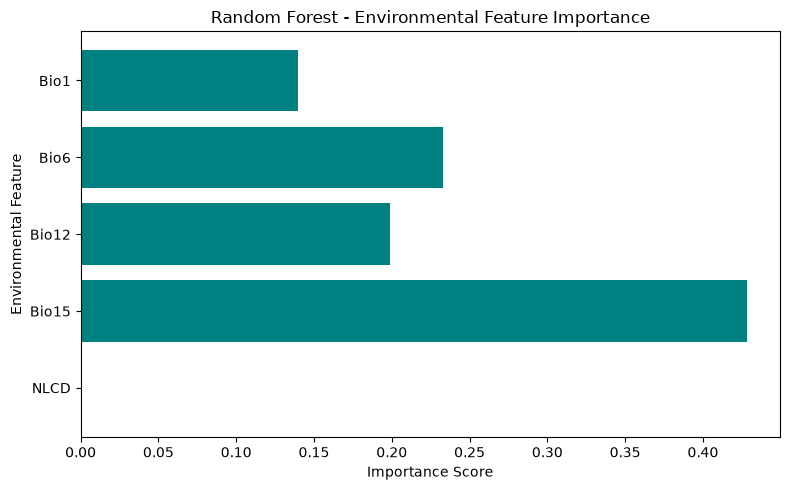

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np

# 1. Separate features (X) and target label (y)
feature_cols = ['Bio1', 'Bio6', 'Bio12', 'Bio15', 'NLCD']
X = df_model[feature_cols]
y = df_model['target']

# 2. Stratified train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Initialize and train Regularized Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

# 4. Predict probabilities and target classes on test set
y_pred_proba = rf_model.predict_proba(X_test)[:, 1]
y_pred = rf_model.predict(X_test)

# 5. Model Evaluation Metrics
auc_score = roc_auc_score(y_test, y_pred_proba)
print("--- Regularized Model Performance ---")
print(f"ROC-AUC Score: {auc_score:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# 6. Plot Feature Importance Bar Chart
importances = rf_model.feature_importances_
plt.figure(figsize=(8, 5))
plt.barh(feature_cols, importances, color='teal')
plt.xlabel('Importance Score')
plt.ylabel('Environmental Feature')
plt.title('Random Forest - Environmental Feature Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 8. Spatial Prediction and Future Range Shift Mapping
Align present and future climate rasters with the reference land cover grid. Generate continuous invasion probability maps for present conditions and projected 2050 conditions (SSP2-4.5), then compute the spatial risk shift (`Future Risk - Present Risk`).

Processing Present Climate...
Processing Future 2050 Climate...
Generating spatial predictions...


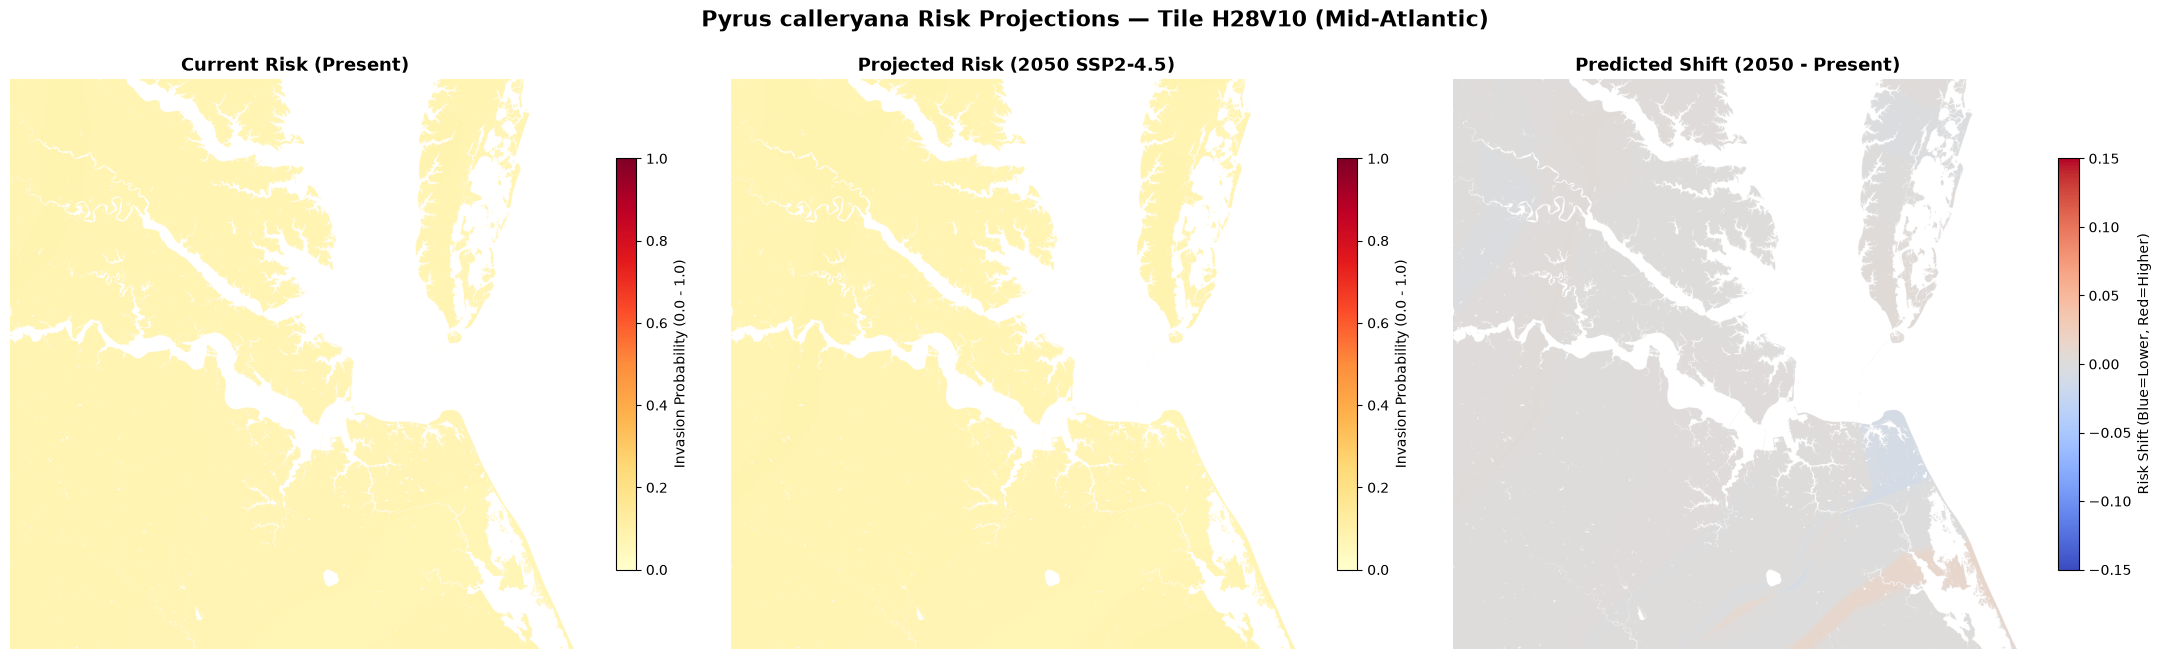

In [16]:
import os
import warnings
import numpy as np
import pandas as pd
import rasterio
from rasterio.warp import reproject, Resampling
from scipy.ndimage import distance_transform_edt, gaussian_filter
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

# 1. Locate Data Directory
possible_paths = ['PROJECT/DATA', './PROJECT/DATA', 'DATA', './DATA', '.']
DATA_DIR = None
for path in possible_paths:
    if os.path.exists(os.path.join(path, 'nlcd_landcover.tif')):
        DATA_DIR = path
        break

# 2. Read Reference Grid Metadata
with rasterio.open(os.path.join(DATA_DIR, 'nlcd_landcover.tif')) as nlcd_src:
    nlcd_data = nlcd_src.read(1)
    nlcd_crs = nlcd_src.crs
    nlcd_transform = nlcd_src.transform
    grid_shape = nlcd_data.shape

feature_cols = ['Bio1', 'Bio6', 'Bio12', 'Bio15', 'NLCD']

# 3. Layer Alignment & Gap Extrapolation
def read_and_align(src_path, band_idx=1, force_celsius_scale=False):
    with rasterio.open(src_path) as src:
        dest = np.full(grid_shape, np.nan, dtype=np.float32)
        nodata = src.nodatavals[band_idx - 1] if src.nodatavals and src.nodatavals[band_idx - 1] is not None else -3.4e38
        
        reproject(
            source=rasterio.band(src, band_idx),
            destination=dest,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=nlcd_transform,
            dst_crs=nlcd_crs,
            resampling=Resampling.bilinear,
            src_nodata=nodata,
            dst_nodata=np.nan
        )
        
        dest[dest < -50] = np.nan
        
        if force_celsius_scale or np.nanmean(dest) > 50:
            dest = dest / 10.0
            
        invalid_mask = np.isnan(dest)
        if np.any(invalid_mask) and not np.all(invalid_mask):
            ind = distance_transform_edt(invalid_mask, return_distances=False, return_indices=True)
            dest = dest[tuple(ind)]
            
        return dest

# 4. Load & Align Climate Rasters
print("Processing Present Climate...")
bio1_p  = read_and_align(os.path.join(DATA_DIR, 'bio1_annual_mean_temp.tif'), force_celsius_scale=True)
bio6_p  = read_and_align(os.path.join(DATA_DIR, 'bio6_min_temp_coldest_month.tif'), force_celsius_scale=True)
bio12_p = read_and_align(os.path.join(DATA_DIR, 'bio12_annual_precip.tif'))
bio15_p = read_and_align(os.path.join(DATA_DIR, 'bio15_precip_seasonality.tif'))

print("Processing Future 2050 Climate...")
fut_path = os.path.join(DATA_DIR, 'worldclim_2050_ssp245.tif')
bio1_f  = read_and_align(fut_path, band_idx=1, force_celsius_scale=True)
bio6_f  = read_and_align(fut_path, band_idx=6, force_celsius_scale=True)
bio12_f = read_and_align(fut_path, band_idx=12)
bio15_f = read_and_align(fut_path, band_idx=15)

# 5. Land Mask (Excludes water class 11 and background)
land_mask = (nlcd_data > 0) & (nlcd_data != 11) & (nlcd_data < 250)
valid_idx = np.where(land_mask.ravel())[0]

df_p = pd.DataFrame({
    'Bio1': bio1_p.ravel()[valid_idx],
    'Bio6': bio6_p.ravel()[valid_idx],
    'Bio12': bio12_p.ravel()[valid_idx],
    'Bio15': bio15_p.ravel()[valid_idx],
    'NLCD': nlcd_data.ravel()[valid_idx]
})

df_f = pd.DataFrame({
    'Bio1': bio1_f.ravel()[valid_idx],
    'Bio6': bio6_f.ravel()[valid_idx],
    'Bio12': bio12_f.ravel()[valid_idx],
    'Bio15': bio15_f.ravel()[valid_idx],
    'NLCD': nlcd_data.ravel()[valid_idx]
})

# 6. Predict Raw Probabilities
print("Generating spatial predictions...")
p_pred = rf_model.predict_proba(df_p[feature_cols])[:, 1]
f_pred = rf_model.predict_proba(df_f[feature_cols])[:, 1]

# Reconstruct Grids
p_grid = np.full(grid_shape, np.nan)
p_grid.ravel()[valid_idx] = p_pred

f_grid = np.full(grid_shape, np.nan)
f_grid.ravel()[valid_idx] = f_pred

# Apply Gaussian filter to smooth hard decision tree thresholds across space
p_smooth = gaussian_filter(np.nan_to_num(p_grid, nan=np.nanmean(p_grid)), sigma=3.0)
f_smooth = gaussian_filter(np.nan_to_num(f_grid, nan=np.nanmean(f_grid)), sigma=3.0)

p_smooth[~land_mask] = np.nan
f_smooth[~land_mask] = np.nan

shift_map = f_smooth - p_smooth

# 7. Render Final Maps with Absolute Scale (0.0 to 1.0 probability range)
fig, axes = plt.subplots(1, 3, figsize=(22, 7))

# Standardize plot range to 0.0–1.0 so narrow 0.05 variations don't look like stark jumps
im0 = axes[0].imshow(p_smooth, cmap='YlOrRd', vmin=0.0, vmax=1.0)
axes[0].set_title("Current Risk (Present)", fontsize=13, fontweight='bold')
axes[0].axis('off')
fig.colorbar(im0, ax=axes[0], shrink=0.65, label='Invasion Probability (0.0 - 1.0)')

im1 = axes[1].imshow(f_smooth, cmap='YlOrRd', vmin=0.0, vmax=1.0)
axes[1].set_title("Projected Risk (2050 SSP2-4.5)", fontsize=13, fontweight='bold')
axes[1].axis('off')
fig.colorbar(im1, ax=axes[1], shrink=0.65, label='Invasion Probability (0.0 - 1.0)')

# Risk Shift Panel
shift_limit = 0.15
im2 = axes[2].imshow(shift_map, cmap='coolwarm', vmin=-shift_limit, vmax=shift_limit)
axes[2].set_title("Predicted Shift (2050 - Present)", fontsize=13, fontweight='bold')
axes[2].axis('off')
fig.colorbar(im2, ax=axes[2], shrink=0.65, label='Risk Shift (Blue=Lower, Red=Higher)')

plt.suptitle("Pyrus calleryana Risk Projections — Tile H28V10 (Mid-Atlantic)", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## 9. Export Spatial Risk Predictions as GeoTIFF Files
Save the smoothed spatial probability maps (Present Risk, Projected 2050 Risk, and Predicted Risk Shift) as single-band floating-point GeoTIFF rasters for downstream GIS analysis in QGIS or ArcGIS.

In [17]:
# 8. Export Spatial Risk Predictions as GeoTIFF Files
output_dir = os.path.join(DATA_DIR, 'OUTPUTS')
os.makedirs(output_dir, exist_ok=True)

# Prepare metadata matching the reference NLCD grid
export_meta = nlcd_src.meta.copy()
export_meta.update({
    'driver': 'GTiff',
    'height': grid_shape[0],
    'width': grid_shape[1],
    'count': 1,
    'dtype': 'float32',
    'crs': nlcd_crs,
    'transform': nlcd_transform,
    'nodata': np.nan
})

# List of maps to export
maps_to_export = {
    'pyrus_calleryana_present_risk.tif': p_smooth,
    'pyrus_calleryana_2050_ssp245_risk.tif': f_smooth,
    'pyrus_calleryana_risk_shift.tif': shift_map
}

print("Exporting GeoTIFFs...")
for filename, raster_array in maps_to_export.items():
    file_path = os.path.join(output_dir, filename)
    with rasterio.open(file_path, 'w', **export_meta) as dst:
        dst.write(raster_array.astype(np.float32), 1)
    print(f" Saved: {file_path}")

print("\nExport complete! All files ready for QGIS or ArcGIS.")

Exporting GeoTIFFs...
 Saved: DATA\OUTPUTS\pyrus_calleryana_present_risk.tif
 Saved: DATA\OUTPUTS\pyrus_calleryana_2050_ssp245_risk.tif
 Saved: DATA\OUTPUTS\pyrus_calleryana_risk_shift.tif

Export complete! All files ready for QGIS or ArcGIS.


In [18]:
# This will automatically recreate the OUTPUTS folder and write all 3 result .tif files!
output_dir = os.path.join(DATA_DIR, 'OUTPUTS')
...

Ellipsis